# Проба. Подготовка данных датчиков

Ячейки выполняются сверху вниз. Для повторного запуска положите `sensors.csv` рядом с тетрадью.

## Исходные данные

`sensors.csv` содержит 10 000 строк и 6 столбцов. Каждая строка содержит показания датчиков и отметку о том, произошла ли авария. Данные учебные.

| Столбец | Что означает |
| --- | --- |
| `t_c` | Температура в градусах Цельсия. |
| `t_f` | Та же температура в градусах Фаренгейта. |
| `hours` | Часы с последнего обслуживания. |
| `mode` | Режим работы устройства. |
| `fw` | Версия программы устройства. |
| `fail` | Была ли авария: 0 — нет, 1 — да. |

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


## Загрузка данных

In [2]:
df = pd.read_csv("sensors.csv") # Загрузить данные из файла
print(df.head()) # Взять первые 5 строк таблицы df


    t_c    t_f  hours    mode  fw  fail
0  34.0   93.2    1.0  normal  v1     0
1  35.0   95.0    2.0     NaN  v1     0
2   NaN    NaN    5.0  normal  v1     0
3   NaN    NaN    5.0  normal  v1     0
4  45.0  113.0   10.0   boost  v1     1


## Поиск пропусков

In [3]:
missing = df.isna().sum() # Посчитать число пропусков в столбцах
share = df.isna().mean() * 100 # Посчитать долю пропусков в процентах
print(pd.DataFrame({"count": missing, "percent": share})) # Показать оба показателя в консоли


       count  percent
t_c      200      2.0
t_f      200      2.0
hours      0      0.0
mode     100      1.0
fw         0      0.0
fail       0      0.0


## Заполнение пропусков


В обеих шкалах температуры пропущено по 200 значений. Заполним их медианами соответствующих столбцов.

In [4]:
median_t_c = df["t_c"].median()
median_t_f = df["t_f"].median()
df["t_c"] = df["t_c"].fillna(median_t_c)
df["t_f"] = df["t_f"].fillna(median_t_f)
print("Медиана t_c:", median_t_c)
print("Медиана t_f:", median_t_f)

Медиана t_c: 36.5
Медиана t_f: 97.7


Для 100 строк режим работы неизвестен. Выделим его в отдельную категорию.

In [5]:
df["mode"] = df["mode"].fillna("неизвестно")

## Обработка дубликатов строк


In [6]:
print(df.duplicated().sum()) # Найти повторные записи



1


In [7]:
df = df.drop_duplicates().copy()
print("Осталось строк:", len(df))

Осталось строк: 9999


## Поиск выбросов


Сравним распределения температур и времени с последнего обслуживания. На нижнем графике отдельные точки показывают значения за пределами усов.

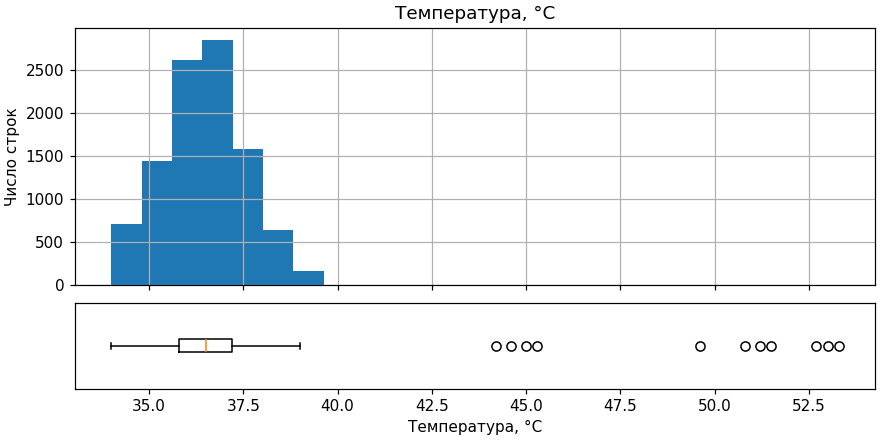

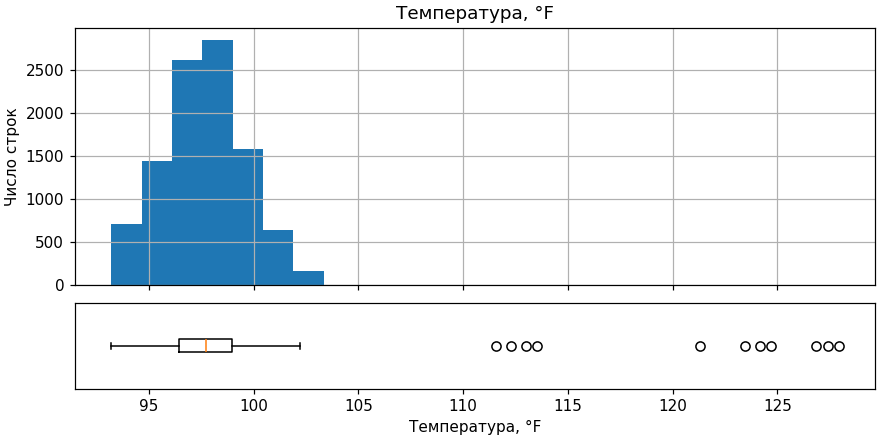

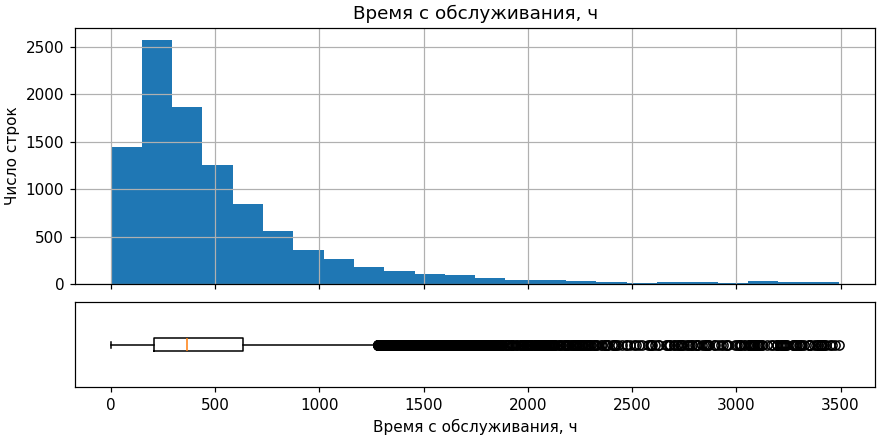

In [8]:
for col, label in [("t_c", "Температура, °C"), ("t_f", "Температура, °F"),
                   ("hours", "Время с обслуживания, ч")]:
    fig, axes = plt.subplots(2, 1, sharex=True, figsize=(8, 4),
                             height_ratios=[3, 1], layout="constrained")
    df[col].hist(bins=24, ax=axes[0])
    axes[0].set_title(label)
    axes[0].set_ylabel("Число строк")
    axes[1].boxplot(df[col], orientation="horizontal", showmeans=False)
    axes[1].set_yticks([])
    axes[1].set_xlabel(label)
    plt.show()

## Обработка выбросов

Основная группа температур лежит в пределах 34–39 °C. Следующая точка — 44,2 °C. Для этой учебной обработки возьмём верхнюю границу 40 °C (104 °F). Все 11 высоких показаний пришлись на строки с аварией, поэтому по одной таблице нельзя установить, была ли это ошибка датчика или реальный перегрев.

In [9]:
print("Строк выше порога:", (df["t_c"] > 40).sum())
df["t_c"] = df["t_c"].mask(df["t_c"] > 40).fillna(median_t_c)
df["t_f"] = df["t_f"].mask(df["t_f"] > 104).fillna(median_t_f)

Строк выше порога: 11


Часы с последнего обслуживания бывают большими. Сохраним эти наблюдения и по условию применим логарифм. После преобразования в hours записан натуральный логарифм от (1 + число часов).

In [10]:
df["hours"] = np.log1p(df["hours"])

## Проверка повторяющихся значений

Проверим, как часто встречается каждая версия программы.

In [11]:
print(df["fw"].nunique()) # Посчитать разные значения


2


In [12]:
counts = df["fw"].value_counts() # Посчитать строки для каждого значения
percent = (counts / counts.sum() * 100).round(1) # Посчитать долю каждой версии в процентах
print(pd.DataFrame({"count": counts, "percent": percent})) # Показать число и долю каждой версии


    count  percent
fw                
v1   9969     99.7
v2     30      0.3


## Удаление лишних признаков

Сравним три числовых признака. Коэффициент корреляции 1 между температурами ожидаем: обе колонки описывают одно измерение.

In [13]:
correlation = df[["t_c", "t_f", "hours"]].corr()
print(correlation)

            t_c       t_f     hours
t_c    1.000000  1.000000  0.004733
t_f    1.000000  1.000000  0.004733
hours  0.004733  0.004733  1.000000


Оставим температуру в градусах Цельсия. Уберём вторую шкалу t_f и столбец fw, где почти во всех строках указана версия v1.

In [14]:
df = df.drop(columns=["t_f", "fw"])

## Преобразование текстовых значений

Преобразуем режимы работы в отдельные столбцы. Единица показывает, какой режим указан в строке.

In [15]:
df = pd.get_dummies(df, columns=["mode"], dtype=int)

## Проверка результата

In [16]:
print("Размер таблицы:", df.shape)
print(df.isna().sum()) # Проверить, что пропусков не осталось
print(df.head(3)) # Показать первые три строки готовой таблицы


Размер таблицы: (9999, 6)
t_c                0
hours              0
fail               0
mode_boost         0
mode_normal        0
mode_неизвестно    0
dtype: int64
    t_c     hours  fail  mode_boost  mode_normal  mode_неизвестно
0  34.0  0.693147     0           0            1                0
1  35.0  1.098612     0           0            0                1
2  36.5  1.791759     0           0            1                0
